# Анализ тональности: LSTM (PyTorch)

Нейросетевой эксперимент с использованием тех же данных и разбиения, что и для классических моделей. Оценка по автоматически созданным меткам RuBERT.

## Загрузка и разделение данных

In [1]:
from pathlib import Path
from collections import Counter
import re
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

torch.manual_seed(42)
torch.set_num_threads(2)
Path('results').mkdir(exist_ok=True)
data = pd.read_csv(Path.home() / 'ML_private_datasets' / 'nlp' / 'my_comments_labeled_corrected.csv')
data = data[['comment_text_clean', 'sentiment_label']].dropna()
data = data[data.comment_text_clean.str.strip().ne('')].drop_duplicates('comment_text_clean')

x_train, x_test, y_train, y_test = train_test_split(data.comment_text_clean, data.sentiment_label, test_size=0.2, stratify=data.sentiment_label, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.25, stratify=y_train, random_state=42)
print('Train:', len(x_train), '| Validation:', len(x_val), '| Test:', len(x_test))

Train: 1983 | Validation: 661 | Test: 662


## Тексты → последовательности чисел

In [2]:
def words(text):
    return re.findall(r'[а-яёa-z0-9]+', text.lower())

counts = Counter(word for text in x_train for word in words(text))
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, count in counts.most_common(8000):
    if count >= 2:
        vocab[word] = len(vocab)

def encode(texts):
    sequences = []
    for text in texts:
        numbers = [vocab.get(w, 1) for w in words(text)[:64]]
        sequences.append(numbers + [0] * (64 - len(numbers)))
    return torch.tensor(sequences, dtype=torch.long)

classes = ['NEGATIVE', 'NEUTRAL', 'POSITIVE']
def encode_y(labels):
    return torch.tensor([classes.index(x) for x in labels], dtype=torch.long)

X_train, X_val, X_test = encode(x_train), encode(x_val), encode(x_test)
Y_train, Y_val, Y_test = encode_y(y_train), encode_y(y_val), encode_y(y_test)

## Нейросеть

In [3]:
model = nn.ModuleDict({
    'embedding': nn.Embedding(len(vocab), 64, padding_idx=0),
    'lstm': nn.LSTM(64, 48, batch_first=True, bidirectional=True),
    'dropout': nn.Dropout(0.4),
    'linear': nn.Linear(96, 3)
})

def predict(x):
    vectors = model['embedding'](x)
    lengths = (x != 0).sum(1).clamp(min=1).cpu()
    packed = nn.utils.rnn.pack_padded_sequence(vectors, lengths, batch_first=True, enforce_sorted=False)
    _, (h, _) = model['lstm'](packed)
    return model['linear'](model['dropout'](torch.cat((h[-2], h[-1]), dim=1)))

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()
loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=64, shuffle=True)

## Обучение и выбор лучшей эпохи

In [4]:
history = []
best_f1 = -1

for epoch in range(18):
    model.train()
    losses = []
    for x, y in loader:
        optimizer.zero_grad()
        loss = loss_fn(predict(x), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    model.eval()
    with torch.no_grad():
        pred = predict(X_val).argmax(1).numpy()
    score = f1_score(Y_val.numpy(), pred, average='macro')
    history.append([epoch + 1, np.mean(losses), score])
    print(f'Epoch {epoch + 1}: F1 = {score:.3f}')
    if score > best_f1:
        best_f1 = score
        best_weights = copy.deepcopy(model.state_dict())

model.load_state_dict(best_weights)
history = pd.DataFrame(history, columns=['epoch', 'train_loss', 'validation_macro_f1'])
history.to_csv('results/lstm_training_history.csv', index=False)

Epoch 1: F1 = 0.251
Epoch 2: F1 = 0.251
Epoch 3: F1 = 0.287
Epoch 4: F1 = 0.305
Epoch 5: F1 = 0.361
Epoch 6: F1 = 0.409
Epoch 7: F1 = 0.423
Epoch 8: F1 = 0.444
Epoch 9: F1 = 0.502
Epoch 10: F1 = 0.510
Epoch 11: F1 = 0.503
Epoch 12: F1 = 0.515
Epoch 13: F1 = 0.540
Epoch 14: F1 = 0.500
Epoch 15: F1 = 0.504
Epoch 16: F1 = 0.504
Epoch 17: F1 = 0.515
Epoch 18: F1 = 0.507


Epoch 2: F1 = 0.251


Epoch 3: F1 = 0.287


Epoch 4: F1 = 0.305


Epoch 5: F1 = 0.361


...

Epoch 14: F1 = 0.500


Epoch 15: F1 = 0.504


Epoch 16: F1 = 0.504


Epoch 17: F1 = 0.515


Epoch 18: F1 = 0.507


## Итоги

LSTM: Accuracy = 0.595, Macro F1 = 0.501
              precision    recall  f1-score   support

    NEGATIVE       0.31      0.32      0.32       142
     NEUTRAL       0.69      0.76      0.72       399
    POSITIVE       0.58      0.38      0.46       121

    accuracy                           0.60       662
   macro avg       0.53      0.49      0.50       662
weighted avg       0.59      0.60      0.59       662



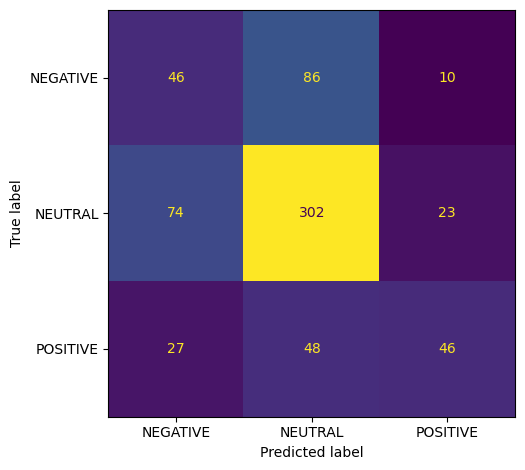

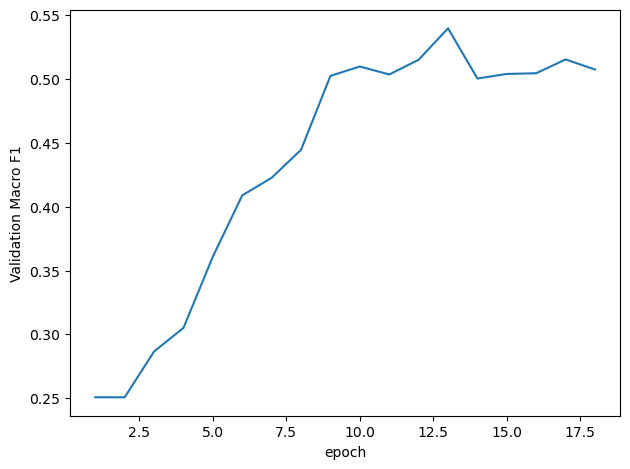

In [5]:
model.eval()
with torch.no_grad():
    pred_ids = predict(X_test).argmax(1).numpy()

pred = [classes[i] for i in pred_ids]
accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average='macro')
print(f'LSTM: Accuracy = {accuracy:.3f}, Macro F1 = {macro_f1:.3f}')
print(classification_report(y_test, pred, zero_division=0))

pd.DataFrame([{'model': 'LSTM', 'test_accuracy': accuracy, 'test_macro_f1': macro_f1}]).to_csv('results/test_lstm.csv', index=False)
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, colorbar=False)
plt.tight_layout()
plt.savefig('results/confusion_matrix_lstm.png', dpi=150)
plt.show()

history.plot(x='epoch', y='validation_macro_f1', legend=False)
plt.ylabel('Validation Macro F1')
plt.tight_layout()
plt.savefig('results/lstm_training.png', dpi=150)
plt.show()

**Ограничение:** метки созданы автоматически. Для оценки реального качества необходим независимый размеченный вручную тестовый набор.